# 4. Near-duplicates with MinHash and LSH (WELFake)

WELFake merges four source datasets, and the same story often appears more than once: re-posted by another site, with
a new headline, an extra intro or a "share this" footer. Exact duplicates were already dropped in cleaning (8,264 rows),
but **near-duplicates** remain. If one copy lands in `train` and another in `test`, a model can score well by
recognizing the text instead of judging it. This notebook finds those near-duplicates so that the *grouped* split can
keep every group in one partition.

The pipeline, implemented from scratch with NumPy and the standard library (`fake_news.similarity`):

| Step | What | Module |
|---|---|---|
| 1. Shingles | article → set of 3-word shingles, hashed with `crc32` | `shingles.py` |
| 2. MinHash | set → 128 minima of random hash functions (estimates Jaccard) | `minhash.py` |
| 3. LSH | 16 bands × 8 rows → candidate pairs, without comparing all 2 billion pairs | `lsh.py` |
| 4. Verify | exact Jaccard of every candidate pair, keep pairs ≥ threshold | `groups.py` |
| 5. Group | union-find over the kept pairs → `doc_id → group_id` | `groups.py` |

The full run is `python scripts/find_near_duplicates.py` (about 1 minute; signatures are cached in `data/interim/`).


In [1]:
%load_ext autoreload
%autoreload 2

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fake_news import config
from fake_news.data import load_clean
from fake_news.data.split import check_split, make_group_split
from fake_news.similarity import lsh, minhash, plots
from fake_news.similarity import near_duplicates as nd
from fake_news.similarity.shingles import jaccard, shingle_ids, words

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)
plots.use_style()

clean = load_clean(columns=["title", "content", "n_words"])
labels = clean.set_index("doc_id")["is_fake"]
report = json.loads((nd.REPORT_DIR / "near_dup_summary.json").read_text())  # written by the script
THRESHOLD = report["settings"]["threshold"]
print(f"{len(clean):,} cleaned articles, {labels.mean():.1%} fake; threshold used: {THRESHOLD}")

62,525 cleaned articles, 44.4% fake; threshold used: 0.7


## 1. Shingles and Jaccard similarity

An article becomes the **set** of its 3-word shingles. Words are runs of letters and digits, so punctuation does not
matter. Each shingle is stored as its `crc32` hash, a 32-bit integer. Python's `hash()` is not used because it is
randomized per process: the same text would get different ids in every run.

The similarity of two articles is the **Jaccard similarity** of their shingle sets, $J(A,B) = |A \cap B| / |A \cup B|$.
Three-word shingles are short enough that an edited copy still shares most of them, and long enough that unrelated
articles share few (common phrases like "the united states" are rare compared with the whole set).

In [2]:
text = "trump signs new tax bill today"
w = words(text)
print([" ".join(w[i:i + 3]) for i in range(len(w) - 2)])
print(shingle_ids(text))

a, b = np.array([1, 2, 3]), np.array([2, 3, 4])
print("J =", jaccard(a, b))

['trump signs new', 'signs new tax', 'new tax bill', 'tax bill today']
[   2934821  580416443 1969217837 3374127782]
J = 0.5


Articles with fewer than 5 distinct shingles (texts of up to about 6 words) get **no signature** and always stay
singletons. They are kept in the data on purpose (cleaning decision G7), but with so few shingles two unrelated
teasers can reach a high Jaccard similarity by chance.

In [3]:
t0 = time.perf_counter()
table = nd.compute_signatures(clean)   # reads data/interim/minhash_signatures.npz if it is up to date
print(f"{'cache' if table.from_cache else 'computed'} in {time.perf_counter() - t0:.1f} s; "
      f"report run took {report['seconds']}")
print(f"signatures: {table.signatures.shape}; {table.n_shingles.sum():,} shingles in total")
print(f"articles without signature (< {nd.MIN_SHINGLES} shingles): {len(table.short_doc_ids)}")
table.n_shingles.describe().round(0).to_frame("distinct shingles per article").T

cache in 0.0 s; report run took {'load': 3.77, 'minhash': 0.03, 'lsh': 2.2, 'verify': 1.7, 'recall': 4.9, 'groups': 0.11}
signatures: (62446, 128); 34,040,779 shingles in total
articles without signature (< 5 shingles): 79


,count,mean,std,min,25%,50%,75%,max
distinct shingles per article,62525.0,544.0,586.0,0.0,244.0,409.0,675.0,23017.0


## 2. MinHash: estimating Jaccard from 128 numbers

For a random hash function $h$, the shingle with the smallest hash in $A \cup B$ is equally likely to be any of its
elements, and $\min h(A) = \min h(B)$ exactly when that shingle lies in $A \cap B$. So
$P[\min h(A) = \min h(B)] = J(A,B)$. With 128 hash functions $h_i(x) = (a_i x + b_i) \bmod P$, where $P = 2^{31}-1$
and $a_i, b_i$ are drawn with `config.SEED`, the share of agreeing positions estimates $J$ with a standard error of
$\sqrt{J(1-J)/128} \le 0.044$. Every article becomes 128 integers, whatever its length.

Overflow: shingle ids are reduced mod $P$ first, so $a x + b < 2^{62} + 2^{31}$ fits in `int64`.

3,954 candidate pairs, verified in 3.0 s


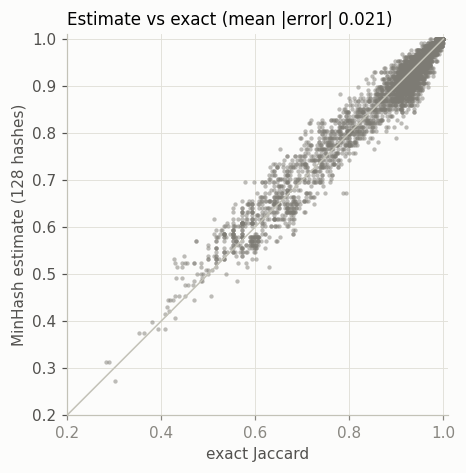

In [4]:
t0 = time.perf_counter()
cands = nd.verify_candidates(nd.find_candidates(table), clean)   # LSH candidates + exact Jaccard (section 3)
print(f"{len(cands):,} candidate pairs, verified in {time.perf_counter() - t0:.1f} s")
fig = plots.estimate_vs_exact(cands)
plots.save(fig, "minhash_estimate_vs_exact")
plt.show()

The estimates scatter around the diagonal as expected. Exact verification still matters near the threshold:
an error of ±0.04 decides whether a pair at 0.72 is kept or not.

## 3. LSH: finding candidate pairs without comparing every pair

All pairs would be 1.9 billion comparisons. **Banding** cuts each signature into 16 bands of 8 values. In each band,
articles with the same 8 values share a bucket, and two articles that share a bucket in at least one band become a
*candidate pair*. A pair with similarity $s$ becomes a candidate with probability $1 - (1 - s^8)^{16}$, an S-curve
around $(1/16)^{1/8} \approx 0.71$:

In [5]:
s = np.array([0.5, 0.6, 0.7, 0.8, 0.9])
pd.DataFrame({"s": s, "P(candidate)": lsh.candidate_probability(s).round(3)}).set_index("s").T

s,0.5,0.6,0.7,0.8,0.9
P(candidate),0.061,0.237,0.613,0.947,1.0


In [6]:
sizes = lsh.bucket_sizes(table.signatures)
n_sig = len(table.doc_ids)
print(f"{len(cands):,} candidate pairs out of {n_sig * (n_sig - 1) // 2:,} possible "
      f"({len(cands) / (n_sig * (n_sig - 1) / 2):.1e} of all pairs)")
print(f"{len(sizes):,} buckets with 2+ articles; largest bucket: {sizes.max()} articles")

3,954 candidate pairs out of 1,949,720,235 possible (2.0e-06 of all pairs)
10,908 buckets with 2+ articles; largest bucket: 38 articles


**How many pairs does 16 × 8 miss?** To check, we band the same signatures more loosely (32 bands × 4 rows,
threshold ≈ 0.42) and verify those candidates as well. The share of the loose banding's pairs that 16 × 8 also finds
estimates our recall. Per similarity bin it should follow the S-curve; above a threshold it is the share of
near-duplicates we actually catch.

In [7]:
loose = nd.verify_candidates(nd.find_candidates(table, bands=32, rows=4), clean)
recall = nd.lsh_recall(cands, loose)
recall

,threshold,reference_pairs,found,recall
0,0.50,6258,3908,0.6245
1,0.60,4430,3687,0.8323
2,0.70,3472,3354,0.9660
3,0.75,3208,3187,0.9935
4,0.80,2997,2991,0.9980
5,0.85,2799,2799,1.0000
6,0.90,2457,2457,1.0000


## 4. Choosing the threshold

Exact Jaccard of all candidate pairs (top) and the LSH S-curve with the measured recall per bin (bottom).
The measured points follow the theoretical curve, which confirms the banding works as intended:

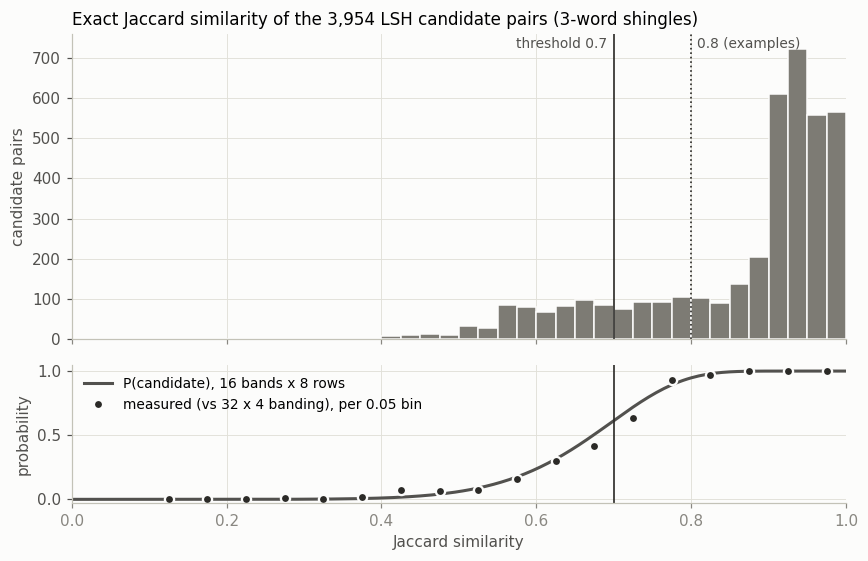

In [8]:
fig = plots.jaccard_histogram(cands, threshold=THRESHOLD, reference=0.8, recall=nd.binned_recall(cands, loose))
plots.save(fig, "minhash_candidate_jaccard")
plt.show()

Most candidates are almost identical (J > 0.9). Below that the histogram is flat down to about 0.55, and below
0.55 it drops, partly because LSH rarely proposes such pairs. Label disagreement does not help to choose: in every bin
fewer than 2% of the pairs mix a fake and a real article.

The pairs just above and just below 0.8 show what the threshold decides. `only_in_a` and `only_in_b` are the words that
differ (from `difflib`):

In [9]:
examples = pd.read_csv(nd.REPORT_DIR / "threshold_examples.csv")
examples[["side", "jaccard", "doc_a", "doc_b", "is_fake_a", "is_fake_b", "n_words_a", "n_words_b",
          "title_a", "title_b", "only_in_a", "only_in_b"]]

,side,jaccard,doc_a,doc_b,is_fake_a,is_fake_b,n_words_a,n_words_b,title_a,title_b,only_in_a,only_in_b
0,above,0.801,41249,53052,1,1,618,642,WikiLeaks CONFIRMS Hillary Sold Weapons to ISIS Then Drops Another BOMBSHELL!,WikiLeaks: Confirms Hillary Sold Weapons To ISIS,then drops another bombshell | theres | hes | hes | obamas | via the duran here is the...,there s | he s | via alternativenews | he s | scroll down for video below | obama s | ...
1,above,0.800,14856,60545,1,1,2472,2442,"Obama, Clinton and Putin Play on the Same Team-America Has Been Betrayed","Obama, Clinton and Putin Play on the Same Team-America Has Been Betrayed",donâ tmt | americaâ tms | annaâ tms | isnâ tmt | russiaâ tms | ofâ russiaâ tms | â | â...,obama clinton and putin play on the same team america has been betrayed previous | don...
2,above,0.800,145,45064,1,1,1347,1474,The Bolton Threat to Trump's Middle East Policy,Will Trump Resist War Hawks on Iran?,the | threat to trump s | policy written by gareth porter post election | us | us | pe...,will trump resist war hawks on iran will trump resist war hawks on iran november 15 20...
3,above,0.800,11152,13345,1,1,49,45,Smart Meter Case Testimony Before the Pennsylvania Public Utility Commission: What No ...,Smart Meter Case Testimony Before the Pennsylvania Public Utility Commission: What No ...,4 | and 3 2016,3
4,above,0.800,12536,24849,1,1,68,72,Somali Home Invasions!,Cancer Patients and Priests Targeted by Googles,somali home invasions | âš,cancer patients and priests targeted by googles
5,above,0.800,12536,42459,1,1,68,72,Somali Home Invasions!,Why Did Four Googles Kill This White?,somali home invasions | âš,why did four googles kill this white
6,above,0.800,20976,32842,1,1,52,59,Boiler Room EP #78,Boiler Room EP #77 - The Venom of Divide and Rule,78,77 the venom of divide and rule
7,above,0.800,37654,43557,1,1,36,40,Newly Approved GM Potatoes Have Potential to Silence Human Genes,Newly Approved GM Potatoes Have Potential to Silence Human Genes,NaN,late | resist potato blight
8,above,0.800,41766,42022,1,1,78,73,Welcome to the 'Islamic State of Germany',PAT CONDELL: America's last chance...,welcome to the islamic state of germany | contact top posts,pat condell america s last chance
9,above,0.800,44352,50521,1,1,45,48,Smart Meter Case Testimony Before the Pennsylvania Public Utility Commission: What No ...,Smart Meter Case Testimony Before the Pennsylvania Public Utility Commission: What No ...,4,3 | and 3 2016


Pairs on **both** sides of 0.8 are the same article with a different headline, intro or footer, or with encoding
differences ("donâ tmt" vs "don t"). Pairs between 0.7 and 0.8 look the same. So 0.8 would split real copies across
partitions. Group statistics for several thresholds:

In [10]:
comparison = nd.threshold_table(clean["doc_id"], cands, labels)
comparison.join(recall.set_index("threshold")["recall"].rename("lsh_recall"))

,verified_pairs,n_articles,groups_2plus,articles_in_groups_2plus,share_articles_in_groups,largest_group,mixed_label_groups,articles_in_mixed_groups,lsh_recall
threshold,,,,,,,,,
0.50,3908,62525,1080,2711,0.0434,42,14,30,0.6245
0.60,3687,62525,1052,2627,0.0420,42,13,28,0.8323
0.70,3354,62525,1002,2445,0.0391,40,13,28,0.9660
0.75,3187,62525,952,2308,0.0369,40,12,26,0.9935
0.80,2991,62525,882,2126,0.0340,40,8,18,0.9980
0.85,2799,62525,806,1924,0.0308,40,7,16,1.0000
0.90,2457,62525,695,1650,0.0264,40,7,16,1.0000


**Proposed threshold: 0.7.**

- Pairs between 0.7 and 0.8 are mostly real copies. Of the 363 such pairs only 23 involve a text shorter than 50
  words, where chance matches are possible.
- For the grouped split, a missed duplicate (a leak between train and test) costs more than a false group (two
  unrelated articles that just share a partition). That argues for the lower end.
- Below 0.7 the 16 × 8 banding stops being reliable: it finds 97% of pairs with J ≥ 0.7, but only 83% of those with
  J ≥ 0.6. A lower threshold would need a different banding (e.g. 32 × 4).
- Going from 0.8 to 0.7 adds 120 groups and about 320 articles. The largest group stays at 40.

## 5. Near-duplicate groups

Pairs with $J \ge$ threshold are edges of a graph, and the groups are its connected components, found with
**union-find**. If A ~ B and B ~ C, all three are one group even when A and C differ more: otherwise B would link
train and test. The group id is the smallest `doc_id` in the group.

In [11]:
groups = nd.load_groups()                     # data/processed/near_dup_groups.csv (written by the script)
assert groups.equals(nd.make_groups(clean["doc_id"], cands, THRESHOLD))   # same as recomputing here
summary = nd.group_summary(groups, labels)
gt = nd.group_table(groups, labels)
{k: v for k, v in summary.items() if k != "group_size_counts"}

{'n_articles': 62525,
 'groups_2plus': 1002,
 'articles_in_groups_2plus': 2445,
 'share_articles_in_groups': 0.0391,
 'largest_group': 40,
 'mixed_label_groups': 13,
 'articles_in_mixed_groups': 28}

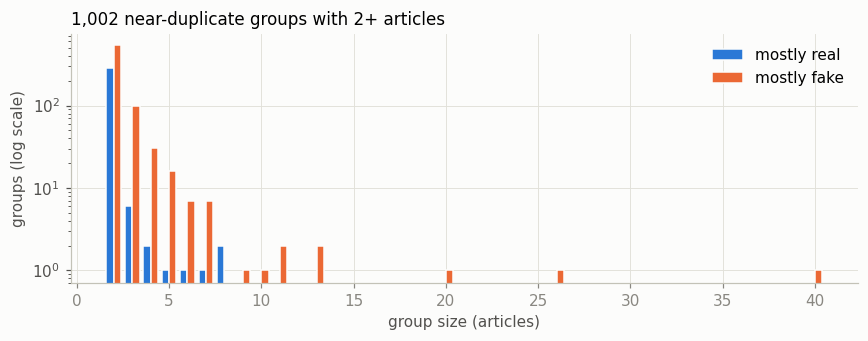

In [12]:
fig = plots.group_sizes(gt)
plots.save(fig, "minhash_group_sizes")
plt.show()

Most groups are pairs. The largest groups are worth a look: what links them?

In [13]:
for gid in gt.index[:4]:
    print(f"group {gid}: {gt.at[gid, 'size']} articles, {gt.at[gid, 'n_fake']} fake")
    display(nd.describe_group(groups, gid, clean, n=4))

group 216: 40 articles, 40 fake


,is_fake,n_words,title,content_start
doc_id,,,,
216,1,327,"Syrian War Report - October 28, 2016: Militants Make Do-Or-Die Attem …","syrian war report - october 28, 2016: militants make do-or-die attempt to break aleppo..."
5694,1,319,Moveable Feast Cafe 2016/11/14 ... Open Thread,moveable feast cafe 2016/11/14 ... open thread. it s preferable that you choose a name...
5959,1,324,New Comment Features have been Added,new comment features have been added. be the first to comment! it s preferable that yo...
6097,1,324,How my family Stopped a Chronic MRSA Infection When Conventional Med …,how my family stopped a chronic mrsa infection when conventional medicine failed. it s...


group 1352: 26 articles, 26 fake


,is_fake,n_words,title,content_start
doc_id,,,,
1352,1,215,Testimonial - 'I can focus better' from Kate,testimonial - i can focus better from kate. click here to learn more about alexandra s...
3234,1,215,"Core Wounds, Soul Family Reunions, and Time Glitches","core wounds, soul family reunions, and time glitches. click here to learn more about a..."
3456,1,218,"Benjamin Fulford Full Update in Spanish & English: October 24, 2016","benjamin fulford full update in spanish & english: october 24, 2016. click here to lea..."
6250,1,212,Alex Collier on Angels 2016-10-22,alex collier on angels 2016-10-22. click here to learn more about alexandra s personal...


group 114: 20 articles, 20 fake


,is_fake,n_words,title,content_start
doc_id,,,,
114,1,4237,CNN: One voter can make a difference by voting repeatedly,cnn: one voter can make a difference by voting repeatedly. channel list following hurr...
153,1,4342,The Glorious New PC NFL Starts Next Monday!,"the glorious new pc nfl starts next monday! afraid of ""dangerous"" trump presidency, pr..."
3480,1,4234,Yogagate: Clinton's instructor received classified emails,yogagate: clinton s instructor received classified emails. channel list following hurr...
5907,1,4370,Obama to pardon HAMILTON cast,"obama to pardon hamilton cast. in hillary s america, email server scrubs you obama tra..."


group 4949: 13 articles, 13 fake


,is_fake,n_words,title,content_start
doc_id,,,,
4949,1,254,Trump's Twitter Access Revoked - The Onion,trump s twitter access revoked - the onion. nation puts 2016 election into perspective...
5247,1,257,5 Things To Know About The Electoral College - The Onion,5 things to know about the electoral college - the onion. nation puts 2016 election in...
7117,1,259,Penn State Fined $2.4 Million For Handling Of Sandusky Case - The On …,penn state fined $2.4 million for handling of sandusky case - the onion. nation puts 2...
7513,1,254,Starbucks 'Unity' Cup Draws Criticism - The Onion,starbucks unity cup draws criticism - the onion. nation puts 2016 election into perspe...


The largest groups are not re-posted stories but **scraping residue**. Their titles all differ, but the body is
the same page element: a comment form ("it s preferable that you choose a name so it becomes clear who said what…",
40 articles), a promo footer ("click here to learn more about alexandra s personalized essences", 26), a site sidebar
("channel list…", 20), or The Onion's "more headlines" box (13). All of them are fake. Keeping each one in a single
partition is exactly right: otherwise a model learns "this boilerplate means fake". They also show that some
widget text survived cleaning.

**Mixed-label groups** (the same text labeled fake and real):

In [14]:
mixed = gt[gt["mixed"]]
print(f"{len(mixed)} mixed groups, {mixed['size'].sum()} articles")
for gid in mixed.index[:4]:
    display(nd.describe_group(groups, gid, clean, n=4))

13 mixed groups, 28 articles


,is_fake,n_words,title,content_start
doc_id,,,,
24117,1,1356,BOMBSHELL: 2006 Audio Emerges Of Hillary Clinton Proposing Rigging P …,bombshell: 2006 audio emerges of hillary clinton proposing rigging palestine election....
41177,1,1251,2006 Audio Emerges of Hillary Clinton Proposing Rigging Palestine El …,2006 audio emerges of hillary clinton proposing rigging palestine election. 2006 audio...
46438,0,1238,2006 Audio Emerges of Hillary Clinton Proposing Rigging Palestine El …,2006 audio emerges of hillary clinton proposing rigging palestine election. on septemb...
66003,1,1419,BOMBSHELL: 2006 Audio Emerges of Crooked Hillary Clinton Proposing R …,bombshell: 2006 audio emerges of crooked hillary clinton proposing rigging palestine e...


,is_fake,n_words,title,content_start
doc_id,,,,
43593,0,568,"In hats and t-shirts, Trump fans rally in Jerusalem's Old City","in hats and t-shirts, trump fans rally in jerusalem s old city. on a rooftop overlooki..."
52074,1,569,"In hats and t-shirts, Trump fans rally in Jerusalem's Old City","in hats and t-shirts, trump fans rally in jerusalem s old city. reuters on a rooftop o..."


,is_fake,n_words,title,content_start
doc_id,,,,
51254,0,567,Syrian political opposition says hopes Clinton wins U.S. presidency,syrian political opposition says hopes clinton wins u.s. presidency. syria s political...
67092,1,705,Assad's Opposition in Syria Favors Clinton Win for President,assad s opposition in syria favors clinton win for president. assad s opposition in sy...


,is_fake,n_words,title,content_start
doc_id,,,,
30393,0,824,U.S. militia girds for trouble as presidential election nears,u.s. militia girds for trouble as presidential election nears. down a georgia country ...
47943,1,840,U.S. militia girds for trouble as presidential election nears,u.s. militia girds for trouble as presidential election nears. u.s. militia girds for ...


Most mixed groups are **Reuters articles re-posted by sites labeled fake**, nearly word for word (J ≈ 0.95-0.99).
WELFake labels by source, so the same text carries both labels. No model can get both right, which puts a small
ceiling on accuracy. Keeping each group in one partition at least stops the conflict from crossing the split.

## 6. Grouped split (preview only)

The groups go to Person 1, who adds `split_grouped` to `splits.csv`. Here we only check that the split can be built and
that no group crosses partitions (`check_split` raises otherwise). `save_split_column` is **not** called.

In [15]:
split = make_group_split(clean[["doc_id", "is_fake"]], groups)
check_split(split, labels=labels, groups=groups)

,n,fraction,fake_rate
split,,,
train,43765,0.70,0.444
val,9380,0.15,0.444
test,9380,0.15,0.444


## 7. Outputs

| File | In git | Contents |
|---|---|---|
| `data/processed/near_dup_groups.csv` | yes | `doc_id, group_id` for all cleaned articles (singletons: `group_id == doc_id`) |
| `data/interim/minhash_signatures.npz` | no | cached signatures (rebuilt automatically when the data changes) |
| `reports/minhash/near_dup_summary.json` | yes | settings, timings, all statistics |
| `reports/minhash/threshold_examples.csv` | yes | 10 pairs just above and below 0.8 |
| `reports/minhash/threshold_comparison.csv` | yes | group statistics per threshold |
| `reports/minhash/largest_groups.csv` | yes | the 25 largest groups and all mixed-label groups |
| `reports/figures/minhash_*.png` | yes | figures of this notebook |

```python
from fake_news.similarity.near_duplicates import load_groups
groups = load_groups()            # pd.Series doc_id -> group_id
```
